In [1]:
import numpy as np
import matplotlib.pyplot as plt
import opt_einsum

In [2]:
A = np.load('A.npy')[:100]
# A = np.tile(A,(1,1,1))
M = np.load('M.npy')
B = A@M
B = B[:,int(B.shape[1]/2):,int(B.shape[2]/2):]
rho_true = np.amax(np.abs(np.linalg.eigvals(B)), axis=-1)

x = np.random.uniform(0,1,size=(B.shape[-1]))
x = x/np.sqrt(np.sum(x**2, axis=-1))
x = np.tile(x,(A.shape[0],1))

In [66]:
x.shape

(100, 100)

In [67]:
B.shape

(100, 100, 100)

In [68]:
rho_max = 0.99
tol = (1 - rho_max)/100
n_iterations = 10000

In [69]:
tol

0.00010000000000000009

In [70]:
reldiffs = np.zeros((n_iterations, A.shape[0]))
rhos = np.zeros((n_iterations, A.shape[0]))

i=1
reldiff = np.ones(A.shape[0])
rho = rho_max*np.zeros(A.shape[0])

while np.amax(reldiff)>tol:
    Bx = opt_einsum.contract('Nij,Nj->Ni', B, x)
    BxTBx = opt_einsum.contract('Ni,Ni->N', Bx, Bx)
    xTBx = opt_einsum.contract('Ni,Ni->N', x, Bx)
    xTx = opt_einsum.contract('Ni,Ni->N', x, x)
    rho_new = xTBx/xTx
    rhos[i] = rho_new

    reldiff = np.abs((rho_new - rho)/rho)
    reldiffs[i] = reldiff

    rho = rho_new
    x = Bx/BxTBx[:,None]

    i+=1
print(i)

26


/tmp/ipykernel_1215447/3032881281.py:16: RuntimeWarning: divide by zero encountered in divide
  reldiff = np.abs((rho_new - rho)/rho)


In [ ]:
def rho_power_iteration(B, x, tol):
    """
    Estimate the spectral radius (largest eigenvalue in magnitude) of a batch of matrices 
    using the power iteration method.

    Args:
    B : ndarray of shape (N, M, M)
        A batch of N symmetric square matrices of shape (M, M) whose spectral radii are to be estimated.
    x : ndarray of shape (M,)
        An initial guess for the eigenvector. This vector is tiled across the batch dimension.
    tol : float
        The convergence tolerance. Iteration continues until the maximum relative change in 
        spectral radius estimates across the batch falls below this threshold.

    Returns:
    rho : ndarray of shape (N,)
        The estimated spectral radii (largest eigenvalues) for each matrix in the batch.
    """
    #Add batch dimension to initial random vector
    x = np.tile(x,(B.shape[0],1))
    #Initialize the relative difference and spectral radius estimate arrays
    reldiff = np.ones(B.shape[0])
    rho = np.ones(B.shape[0])
    i=0
    while np.amax(reldiff)>tol:
        #Compute new spectral radius estimate
        Bx = opt_einsum.contract('Nij,Nj->Ni', B, x)
        xTBx = opt_einsum.contract('Ni,Ni->N', x, Bx)
        xTx = opt_einsum.contract('Ni,Ni->N', x, x)
        rho_new = xTBx/xTx
        #Compute absolute relative difference between estimate and previous estimate
        reldiff = np.abs((rho_new - rho)/rho)
        #Update spectral radius estimate
        rho = rho_new
        #Update eigenvector estimate
        BxTBx = opt_einsum.contract('Ni,Ni->N', Bx, Bx)
        x = Bx/BxTBx[:,None]
        i+=1
    return rho


In [7]:
x = np.random.uniform(0,1,B.shape[-1])

In [18]:
rho = rho_power_iteration(B=B, x=x, tol=1e-4)

24


In [19]:
rho

array([0.98951422, 0.98975965, 0.99008029, 0.98959335, 0.99006091,
       0.9897726 , 0.9881299 , 0.98988866, 0.98687234, 0.98930532,
       0.98878216, 0.99025633, 0.99042106, 0.99114457, 0.98972568,
       0.98770201, 0.98924018, 0.98953509, 0.9889086 , 0.98960275,
       0.98825951, 0.98739005, 0.9890315 , 0.98731284, 0.98825819,
       0.99027427, 0.98971606, 0.98947513, 0.98883076, 0.99137172,
       0.98948838, 0.98952203, 0.98972105, 0.98742051, 0.98925294,
       0.98909639, 0.98951667, 0.98830805, 0.98929167, 0.98835333,
       0.98819084, 0.98673088, 0.98977634, 0.98966542, 0.98948857,
       0.98939958, 0.98885211, 0.9901736 , 0.98984816, 0.99025721,
       0.98897949, 0.98974741, 0.98807007, 0.98906912, 0.98742841,
       0.98867132, 0.9896304 , 0.98951124, 0.98957775, 0.99008623,
       0.98953035, 0.98835263, 0.98946536, 0.9902435 , 0.98886015,
       0.9897274 , 0.98956967, 0.98970594, 0.98958057, 0.98742673,
       0.9895305 , 0.98898337, 0.98944158, 0.98790384, 0.98967

In [35]:
reldiffs.shape

(10000, 100)

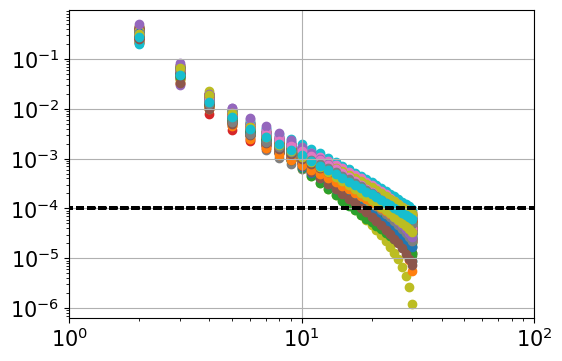

In [54]:
size_title = 20
size_ticklabels = 15
size_axeslabels = 20

fig, ax = plt.subplots(1,1, figsize=(6, 4))
fig.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.4, hspace=0.4)

plots = []
m=0
ax.tick_params(axis='both', labelsize=size_ticklabels)
# ax.scatter(np.arange(len(reldiffs.shape[0])),np.abs(rhos - rho_true)/rho_true, label =r'$|\rho_i - \rho_{\mathrm{true}}|/\rho_{\mathrm{true}}$')
for i in range(A.shape[0]):
    plt.scatter(np.arange(reldiffs.shape[0]),reldiffs[:,i], label=r'$|\rho_i - \rho_{i-1}|/\rho_{i-1}$')
ax.plot(np.arange(len(reldiffs)),np.ones_like(reldiffs)*tol, label='Tolerance', color='black', linestyle='--')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(1e0,1e2)
# ax.legend(fontsize=10)
ax.grid()

# plt.savefig("eigenvalues.svg", bbox_inches='tight')#, transparent=True)

plt.show()

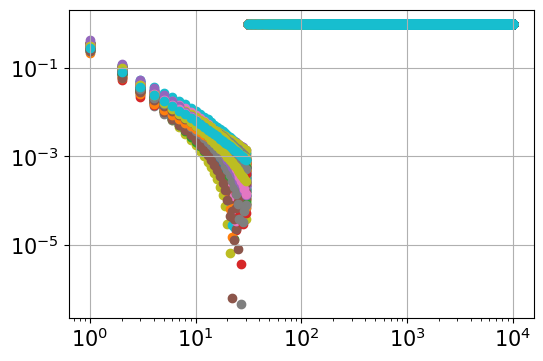

In [55]:
size_title = 20
size_ticklabels = 15
size_axeslabels = 20

fig, ax = plt.subplots(1,1, figsize=(6, 4))
fig.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.4, hspace=0.4)

plots = []
m=0
ax.tick_params(axis='both', labelsize=size_ticklabels)
# ax.scatter(np.arange(len(reldiffs.shape[0])),np.abs(rhos - rho_true)/rho_true, label =r'$|\rho_i - \rho_{\mathrm{true}}|/\rho_{\mathrm{true}}$')
for i in range(A.shape[0]):
    plt.scatter(np.arange(n_iterations),np.abs((rhos - rho_true)/rho_true)[:,i], label=r'$|\rho_i - \rho_{i-1}|/\rho_{i-1}$')
# ax.plot(np.arange(len(reldiffs)),np.ones_like(reldiffs)*tol, label='Tolerance', color='black', linestyle='--')
ax.set_xscale('log')
ax.set_yscale('log')
# ax.legend(fontsize=10)
ax.grid()

# plt.savefig("eigenvalues.svg", bbox_inches='tight')#, transparent=True)

plt.show()